# Модель задержки оплаты по УПД: обучение и проверка
Версия delay-1.0 · «Смарт-факторинг» · по ТЗ «Обучение модели задержки оплаты по УПД» v1.2, раздел 8

Ноутбук показывает выборку, признаки, параметры, результаты на проверочном периоде, ROC, калибровку по децилям, важность признаков, смещение `expected_days` и проверки на утечку. Долгие шаги (подбор параметров на всех десяти партиях, обучение, проверка) выполнены скриптами `dl_dataset.py`, `dl_train.py`, `dl_eval.py`, их результаты лежат в `art/`; здесь они показаны, а выборка, признаки и `score_delay` пересчитываются вживую на тестовой партии.

**Что значат метрики.** Реальных оплат УПД у нас нет, данные синтетические. Метрики показывают, что модель восстанавливает заложенные в данные зависимости и не смотрит в будущее. О качестве на реальных оплатах они ничего не говорят.

**Правило.** Проверочный период (месяцы 25–29) в подборе параметров, калибровке и выборе признаков не участвовал.

In [1]:
import json, os, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import dl_common as dc, dl_dataset as dd, dl_model as dm, score_delay as sd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
R = json.load(open("art/eval_results.json", encoding="utf-8"))
S = json.load(open("art/search.json", encoding="utf-8"))
DS = json.load(open("art/dataset_summary.json", encoding="utf-8"))
TEST_BATCH = os.environ.get("DELAY_TEST_DIR", "../delivery/batch_01")
TRUTH = os.environ.get("DELAY_TRUTH", "../full/truth_upd.parquet")
print("тестовая партия:", TEST_BATCH)

тестовая партия: ../delivery/batch_01


## 1. Данные и сверка оплат
Партия читается из CSV по контракту данных, как её увидит продукт. Оплаты распределяются по УПД правилами Б.2 (номер УПД, номер договора, самый старый открытый, остаток переносится дальше). Из этого получаем дату закрытия каждого УПД.

In [2]:
tab = dc.load_csv_batch(TEST_BATCH)
U, A = dc.reconcile(tab)
print({k: len(v) for k, v in tab.items()}, "| событий распределения:", len(A))
tr = pd.read_parquet(TRUTH).set_index("upd_id")
m = U.set_index("upd_id").join(tr[["full_pay_date", "open_at_d_end"]])
closed = m.close_d.notna()
same = (m.close_d[closed].values == dc.day_int(m.full_pay_date[closed])).mean()
print("УПД: %d, закрыто на D_end: %d, открыто: %d" % (len(U), closed.sum(), (~closed).sum()))
print("даты закрытия по сверке совпадают с правдой генератора: %.1f%%" % (100 * same))

{'upd': 23325, 'pay': 24601, 'cl': 100, 'by': 297} | событий распределения: 26633


УПД: 23325, закрыто на D_end: 21787, открыто: 1538
даты закрытия по сверке совпадают с правдой генератора: 100.0%


## 2. Выборка: строки, метки, части по времени
Строка — УПД и дата `t`: дата подписания и далее каждые 14 дней, пока УПД открыт и срок не наступил. Все строки одного УПД попадают в одну часть (по дате подписания). Метка «задержка больше k дней»: 1, если УПД закрыт с такой задержкой или остаётся открытым дольше k дней после плановой даты; 0, если закрыт с задержкой не больше k; иначе строку для этого k не берём. Метки считаются по наблюдаемым данным, правда не используется.

In [3]:
b = dd.part_bounds()
part = dd.part_of(U.upd_d.values, b)
rows = dc.make_rows(U, b["d_end"], mask=(part != "history"))
lab = dc.make_labels(U, rows, b["d_end"])
rows["part"] = part[rows.u.values]
print("тестовая партия, строк по частям:", rows.part.value_counts().to_dict())
pd.concat([rows.head(6), lab.head(6)], axis=1)

тестовая партия, строк по частям: {'train': 47357, 'test': 16499, 'gap': 12460, 'rest': 10486}


,u,t,j,part,y7,y14,y30,y90,delay_obs
0,0,19793,0,train,1.0,0.0,0.0,0.0,10.0
1,0,19807,1,train,1.0,0.0,0.0,0.0,10.0
2,1,19796,0,train,0.0,0.0,0.0,0.0,0.0
3,1,19810,1,train,0.0,0.0,0.0,0.0,0.0
4,2,19829,0,train,0.0,0.0,0.0,0.0,0.0
5,3,19849,0,train,0.0,0.0,0.0,0.0,0.0


In [4]:
t = pd.DataFrame(DS["parts"]).T.rename(columns={"rows": "строк", "upds": "УПД", "rows_no_history": "строк no_history", "rows_sign": "строк подписания"})
t.index = [{"train": "обучение (месяцы 4–20)", "gap": "пропуск (21–24)", "test": "проверка (25–29)", "rest": "остаток окна (30–33)"}[i] for i in t.index]
print("границы частей:", DS["bounds_dates"])
t

границы частей: {'start': '2023-03-30', 'b3': '2023-06-30', 'b20': '2024-11-30', 'b24': '2025-03-30', 'b29': '2025-08-30', 'd_end': '2025-12-30'}


,строк,УПД,строк no_history,строк подписания
пропуск (21–24),119569,29151,420,29151
остаток окна (30–33),103213,32325,126,32325
проверка (25–29),159597,38790,3,38790
обучение (месяцы 4–20),447040,108757,4644,108757


In [5]:
pd.DataFrame({"обучение": {k: v["rate"] for k, v in DS["labels_train"].items()}, "проверка": {k: v["rate"] for k, v in DS["labels_test"].items()}}).rename_axis("задержка больше, дн.").round(4)

,обучение,проверка
"задержка больше, дн.",,
7,0.3754,0.3735
14,0.2405,0.2497
30,0.0930,0.1106
90,0.0201,0.0216


## 3. Признаки
Только то, что известно на дату `t`: УПД и платежи не позже `t`. Признаки истории считаются по закрытым УПД пары и покупателя **внутри партии**. Не берём: тип стоп-фактора и сам стоп-фактор, содержимое `truth_upd`, идентификаторы.

In [6]:
sub = rows[rows.part != "history"].sample(2000, random_state=1)
X = dc.features(tab, U, A, sub, sorted(tab["cl"].industry.unique()))
print(len(dc.FEATURES), "признаков")
X[dc.FEATURES].describe().T[["count", "mean", "min", "50%", "max"]].round(3)

42 признаков


,count,mean,min,50%,max
amount_mln,2000.0,3.541,0.207,2.255,36.195
deferral_days,2000.0,59.738,15.000,60.000,90.000
days_since_signed,2000.0,26.061,0.000,28.000,84.000
days_to_plan,2000.0,33.676,1.000,31.000,90.000
paid_share,2000.0,0.051,0.000,0.000,0.700
plan_month,2000.0,6.899,1.000,7.000,12.000
plan_qend,2000.0,0.155,0.000,0.000,1.000
plan_yend,2000.0,0.054,0.000,0.000,1.000
amount_ratio,1997.0,1.134,0.167,0.987,7.818
pair_n,2000.0,36.972,0.000,30.000,159.000


## 4. Подбор параметров и калибровка
Кросс-валидация на обучающем периоде: пять частей, группы по УПД. Три конфигурации бустинга на каждый порог, число деревьев по ранней остановке.

In [7]:
rows_ = []
for k, v in S["search"].items():
    rows_.append(dict(порог=int(k), конфигурация=v["config"], деревьев=v["iters"], logloss=v["cv"]["logloss"], AUC_cv=v["cv"]["auc_sign"], AUC_наивного=v["cv"]["auc_naive_sign"], AUC_потолка=v["cv"]["auc_ceiling_sign"]))
pd.DataFrame(rows_).round(4)

,порог,конфигурация,деревьев,logloss,AUC_cv,AUC_наивного,AUC_потолка
0,7,B,499,0.5468,0.7656,0.7295,0.7872
1,14,C,581,0.4673,0.7654,0.7091,0.7842
2,30,B,215,0.2712,0.7654,0.6636,0.7863
3,90,B,97,0.0912,0.7367,0.5561,0.7679


In [8]:
pd.DataFrame({k: {**{a: round(b, 5) for a, b in v["logloss"].items()}, "выбрано": v["kind"]} for k, v in S["calibration"].items()}).T.rename_axis("порог")

,none,platt,isotonic,выбрано
порог,,,,
7,0.54691,0.54691,0.54723,platt
14,0.46741,0.46743,0.46779,platt
30,0.27124,0.27143,0.27156,platt
90,0.0912,0.09129,0.09138,platt


## 5. Проверка: месяцы 25–29
Метрики на строках, где `t` — дата подписания УПД (одна строка на УПД). Потолок — AUC скрытых вероятностей генератора на тех же строках.

In [9]:
pd.DataFrame({k: {"AUC модели": v["model"], "наивное правило": v["naive"], "потолок": v["ceiling"], "прирост к наивному": v["model"] - v["naive"], "УПД": v["n_sign"], "доля задержек": v["pos_rate"]} for k, v in R["auc"].items()}).T.rename_axis("порог").round(4)

,AUC модели,наивное правило,потолок,прирост к наивному,УПД,доля задержек
порог,,,,,,
7,0.7787,0.7712,0.7948,0.0075,38787.0,0.3439
14,0.7729,0.7591,0.7981,0.0137,38787.0,0.2219
30,0.7688,0.7364,0.8171,0.0324,38787.0,0.0961
90,0.7425,0.6469,0.7935,0.0955,38568.0,0.0204


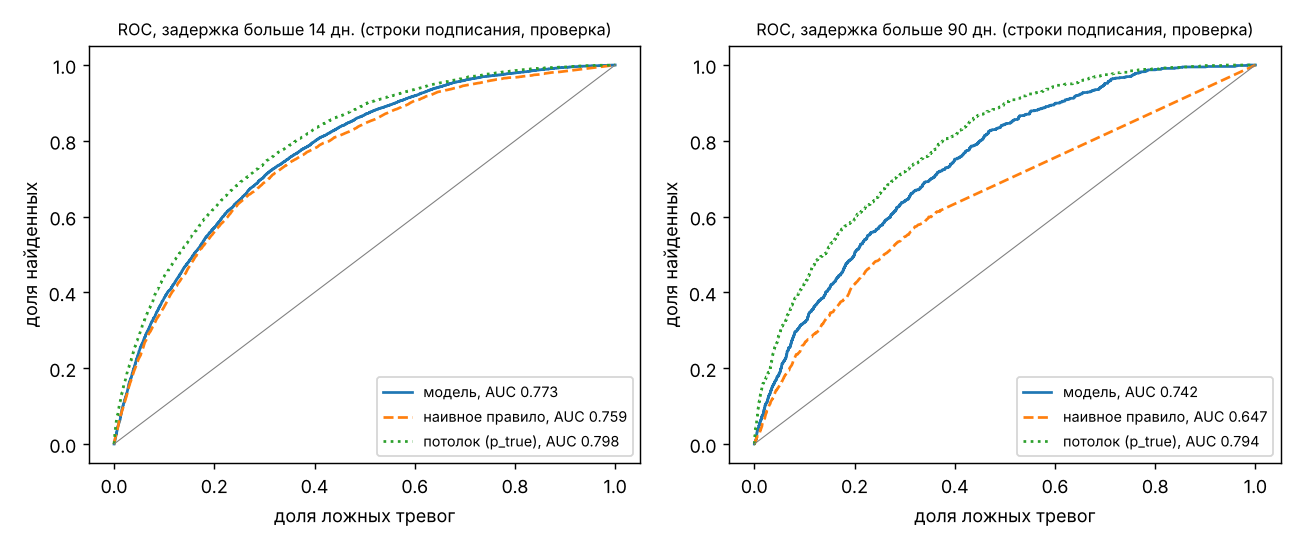

In [10]:
display(Image("art/figs/roc.png"))

**Калибровка по децилям** (средняя оценка против фактической доли задержек в дециле):

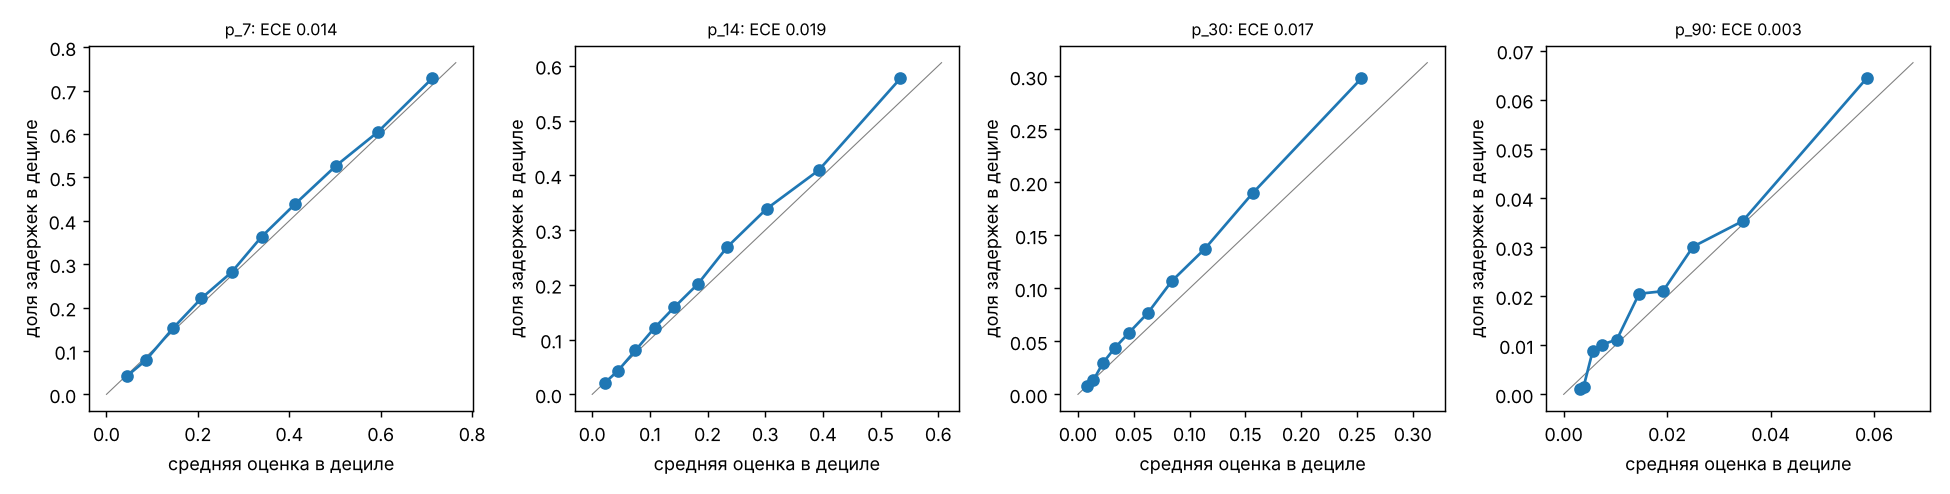

,ECE (строки подписания),ECE (все строки),средняя оценка,доля задержек
7,0.0139,0.0112,0.3321,0.3439
14,0.0187,0.0199,0.2037,0.2219
30,0.0169,0.0201,0.0793,0.0961
90,0.0030,0.0034,0.0182,0.0204


In [11]:
display(Image("art/figs/calibration.png"))
pd.DataFrame({k: {"ECE (строки подписания)": v["ece_sign"], "ECE (все строки)": v["ece_all"], "средняя оценка": v["mean_pred_sign"], "доля задержек": v["mean_obs_sign"]} for k, v in R["calibration"].items()}).T.round(4)

**Монотонность.** Средняя `p_14` по уровням покупателя A–D и по пяти группам суммы УПД к обычной для пары:

In [12]:
display(pd.DataFrame(R["monotony"]["level"]).rename(columns={"index": "уровень", "p14": "средняя p_14", "obs": "факт"}).round(4))
pd.DataFrame(R["monotony"]["amount"]).rename(columns={"aq": "группа", "p14": "средняя p_14", "obs": "факт", "ratio": "сумма к обычной"}).round(4)

,уровень,средняя p_14,факт,n
0,A,0.0819,0.0949,11112
1,B,0.1571,0.1768,10046
2,C,0.2662,0.2914,8638
3,D,0.3929,0.4096,6916


,группа,средняя p_14,факт,сумма к обычной,n
0,0,0.1864,0.2078,0.5835,7758
1,1,0.1877,0.1950,0.8081,7757
2,2,0.1896,0.2119,1.0000,7757
3,3,0.2048,0.2225,1.2522,7757
4,4,0.2502,0.2724,2.1099,7758


**Важность признаков** (доля прироста качества по деревьям):

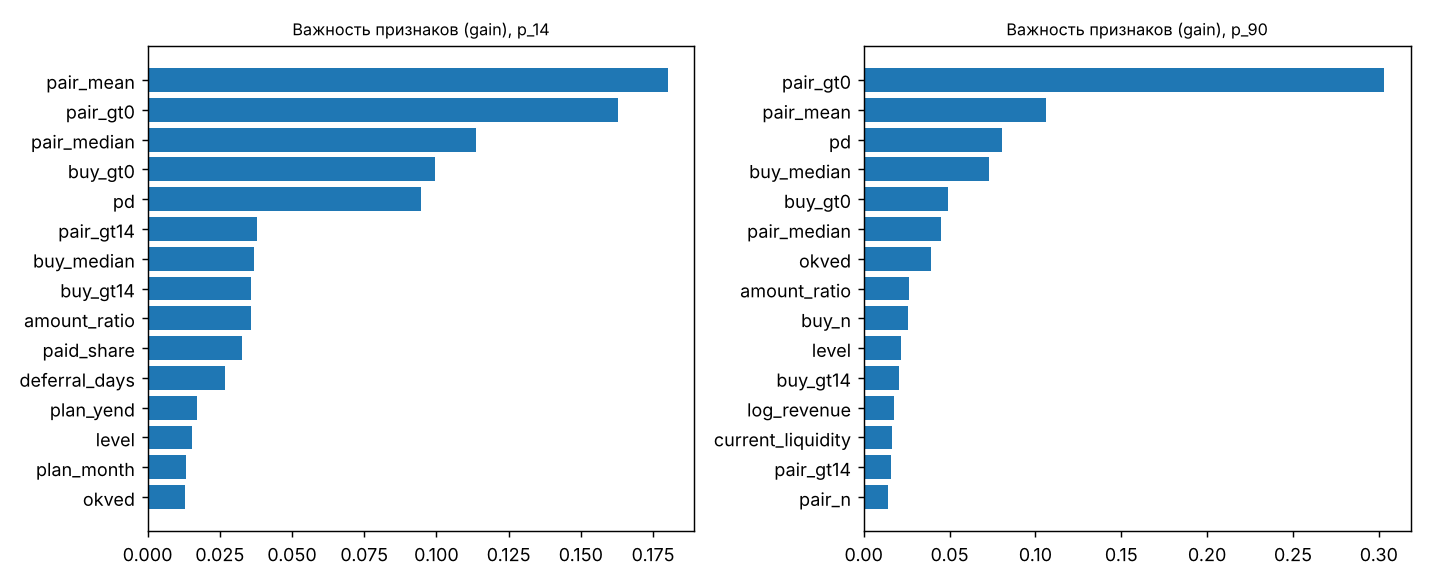

In [13]:
display(Image("art/figs/importance.png"))

## 6. Ожидаемые дни
Регрессия на закрытых УПД. Смещение из-за того, что берутся только закрытые, оценено по `truth_upd`: в проверочном периоде ещё открытые УПД имеют самые длинные задержки.

In [14]:
e = R["expected_days"]
pd.Series({
 "смещение к закрытым УПД, дн.": e["sign_bias_model"],
 "смещение к полной правде, дн.": e["sign_bias_vs_truth_all"],
 "средняя задержка проверки: закрытые / вся правда": "%.2f / %.2f" % (e["selection_test"]["mean_true_closed"], e["selection_test"]["mean_true_all"]),
 "средняя задержка обучения: закрытые / вся правда": "%.2f / %.2f" % (e["selection_train"]["mean_true_closed"], e["selection_train"]["mean_true_all"]),
 "MAE модели / медиана по паре / ноль": "%.2f / %.2f / %.2f" % (e["sign_mae_model"], e["sign_mae_pair_median"], e["sign_mae_zero"]),
 "RMSE модели / среднее по паре / медиана по паре": "%.2f / %.2f / %.2f" % (e["sign_rmse_model"], e["sign_rmse_pair_mean"], e["sign_rmse_pair_median"]),
 "RMSE точного среднего генератора": e["sign_rmse_oracle_mean"],
 "корреляция с точным средним генератора": e["sign_corr_model_oracle"]}).to_frame("значение")

,значение
"смещение к закрытым УПД, дн.",0.913161
"смещение к полной правде, дн.",-1.453043
средняя задержка проверки: закрытые / вся правда,9.21 / 11.70
средняя задержка обучения: закрытые / вся правда,10.52 / 10.54
MAE модели / медиана по паре / ноль,9.99 / 8.24 / 9.21
RMSE модели / среднее по паре / медиана по паре,17.57 / 17.79 / 18.49
RMSE точного среднего генератора,17.45827
корреляция с точным средним генератора,0.833421


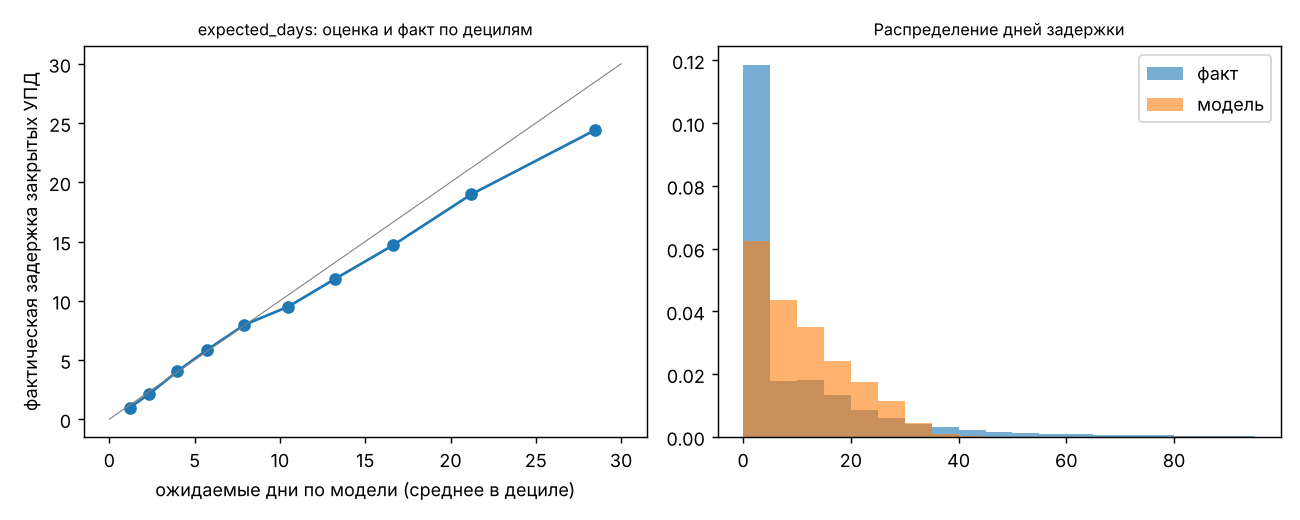

In [15]:
display(Image("art/figs/expected_days.png"))

## 7. Проверка на утечку, скорость, повторяемость

In [16]:
print("перемешанные метки обучения, p_14, пять запусков:", [round(x, 3) for x in R["shuffle"]["train_shuffled_each"]], "среднее", round(R["shuffle"]["train_shuffled"], 3))
print("перемешанные метки проверки, p_14:", round(R["shuffle"]["test_labels_shuffled"], 3))
print("признаки по урезанным до t таблицам:", R["truncation_test"])
print("скорость:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in R["speed"].items()})

перемешанные метки обучения, p_14, пять запусков: [0.478, 0.537, 0.531, 0.484, 0.522] среднее 0.511
перемешанные метки проверки, p_14: 0.501
признаки по урезанным до t таблицам: {'rows': 400, 'rows_with_diff': 0, 'max_abs_diff': 0.0}
скорость: {'n_open': 1219, 'single_mean': 0.039, 'single_max': 0.053, 'batch_seconds': 0.537, 'load_seconds': 0.119, 'repeatable': True}


**Те же оценки вживую.** `score_delay` по CSV тестовой партии на `D_end` и сверка с файлом `delay_scores.csv` партии:

In [17]:
model = sd.get_model()
ids = pd.read_csv(os.path.join(TEST_BATCH, "delay_scores.csv"), dtype=str).upd_id.tolist()
import time; t0 = time.time()
out = sd.score_delay(ids, "2025-12-30", TEST_BATCH, model)
ref = pd.read_csv(os.path.join(TEST_BATCH, "delay_scores.csv"), dtype={"upd_id": str})
cols = ["p_7", "p_14", "p_30", "p_90", "expected_days"]
diff = (out[cols].astype(float).round({"p_7": 6, "p_14": 6, "p_30": 6, "p_90": 6, "expected_days": 2}).fillna(-1).values - ref[cols].astype(float).fillna(-1).values)
print("УПД: %d за %.2f с; макс. расхождение с delay_scores.csv: %.6f; статусы: %s" % (len(out), time.time() - t0, np.abs(diff).max(), out.status.value_counts().to_dict()))
out.head()

УПД: 1219 за 0.85 с; макс. расхождение с delay_scores.csv: 0.000000; статусы: {'ok': 1210, 'no_history': 9}


,upd_id,as_of_date,p_7,p_14,p_30,p_90,expected_days,model_version,status
0,UPD-0020874,2025-12-30,0.811368,0.586146,0.201745,0.044959,25.547862,delay-1.0,ok
1,UPD-0020882,2025-12-30,0.285813,0.232769,0.049092,0.006436,7.270408,delay-1.0,ok
2,UPD-0020885,2025-12-30,0.828048,0.677760,0.223490,0.049425,29.475245,delay-1.0,ok
3,UPD-0020887,2025-12-30,0.566303,0.436344,0.082457,0.015216,14.439654,delay-1.0,ok
4,UPD-0020891,2025-12-30,0.648199,0.474630,0.104268,0.018924,12.804957,delay-1.0,ok


## 8. Итоги по критериям раздела 8.5

In [18]:
cr = pd.DataFrame(R["criteria"]); cr["итог"] = np.where(cr.passed, "прошла", "НЕ ПРОШЛА")
cr[["name", "requirement", "value", "итог"]].rename(columns={"name": "проверка", "requirement": "требование", "value": "значение"})

,проверка,требование,значение,итог
0,"AUC p_14 не ниже потолка минус 0,08",≥ 0.718,0.772887,прошла
1,AUC p_14 выше наивного правила не меньше чем н...,≥ 0.789,0.772887,НЕ ПРОШЛА
2,"AUC p_90 не ниже потолка минус 0,10",≥ 0.694,0.742458,прошла
3,ECE p_7 (строки подписания),"≤ 0,03",0.013894,прошла
4,ECE p_14 (строки подписания),"≤ 0,03",0.018668,прошла
5,ECE p_30 (строки подписания),"≤ 0,03",0.016943,прошла
6,ECE p_90 (строки подписания),"≤ 0,03",0.003045,прошла
7,Средняя p_14 растёт от уровня A к D,A < B < C < D,0.082 / 0.157 / 0.266 / 0.393,прошла
8,Средняя p_14 растёт с ростом суммы к обычной д...,по пяти группам не убывает,0.186 / 0.188 / 0.190 / 0.205 / 0.250,прошла
9,MAE expected_days на закрытых УПД не хуже меди...,≤ 8.24,9.991831,НЕ ПРОШЛА


Не выполнены три пункта: прирост к наивному правилу по `p_14` (+0,014 вместо +0,03), MAE `expected_days` против медианы по паре (среднее по определению проигрывает медиане по MAE, у точного среднего генератора тоже 10,09), К-11 в трёх партиях (отдельный отчёт о покрытии). Подробности и причины: `Delay_Model_Report.md`.

**Ограничения.** Данные синтетические. Оценки в проверочные месяцы в среднем на 1–2 п.п. ниже фактической доли: задержек стало больше, чем в обучении. Для УПД, у которых нет закрытых УПД ни у пары, ни у покупателя, функция возвращает статус `no_history` без вероятностей. Пара без истории, но с покупателем с историей, оценивается по истории покупателя.